# Artist identity probes: results

Linear probes predict the artist of a song from the mean-pooled activations recorded while ACE-Step 1.5 generated it
from the lyrics alone (WIMU-21). This notebook only reads and plots the tables written by the probe script; it trains
nothing.

To regenerate the inputs:

```bash
make generate CSV="outputs/anonymized_50songs/lyrics_*.csv" GENERATED_DIR=outputs/generated_50songs
make probe GENERATED_DIR=outputs/generated_50songs LYRICS_DIR=outputs/anonymized_50songs PROBE_DIR=outputs/probe_50songs
```

Protocol (see `encoder_exorcist/probing.py`): multinomial logistic regression, 5-fold CV grouped by song, 95% Wilson
CI, permutation test with 1000 permutations for the stream outputs, the lyric encoder layers and the baselines.
Hook points are described in `docs/hook_points.md`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from encoder_exorcist.activation_recorder import DIT_LAYERS
from encoder_exorcist.data.lyrics_dataset import PROJECT_ROOT, load_records

CONFIG = "no-cot"  # or "with-cot"
# The 50-songs-per-artist run; the first 20-songs run is in outputs/probe and outputs/anonymized.
PROBE_DIR = PROJECT_ROOT / "outputs" / "probe_50songs" / CONFIG
LYRICS_DIR = PROJECT_ROOT / "outputs" / "anonymized_50songs"

results = pd.read_csv(PROBE_DIR / "results.csv").set_index("point")
per_artist = pd.read_csv(PROBE_DIR / "per_artist.csv")
CHANCE = results["chance"].iloc[0]
acc = results["accuracy"]

# Colors: validated categorical slots 1-5 (dataviz reference palette, light), text and grid in neutral inks.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_2,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "lines.linewidth": 2,
    }
)


def reference_line(ax, y, label, style="--"):
    """Horizontal reference (chance or a baseline), labelled at the right end in text ink."""
    ax.axhline(y, color=INK_2, linewidth=1, linestyle=style, zorder=1)
    ax.annotate(
        f"{label} {y:.0%}",
        (1, y),
        xycoords=("axes fraction", "data"),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=INK_2,
    )


print(
    f"{CONFIG}: {int(results['n_songs'].iloc[0])} songs, {int(results['n_artists'].iloc[0])} artists, "
    f"chance = {CHANCE:.0%}, {len(results)} probes"
)

no-cot: 1000 songs, 20 artists, chance = 5%, 305 probes


## Summary

Stream outputs, lyric encoder layers and the two baselines (lyrics only, no model). `text_out` and `timbre_out` are controls: in no-cot both are the same for every song, so they must stay at chance.

In [2]:
summary_points = [
    "tfidf",
    "qwen3_tokens",
    *[f"lyric_L{i}" for i in range(8)],
    "lyric_out",
    "merged_out",
    "cond_embed_out",
    "text_out",
    "timbre_out",
]
table = results.loc[summary_points, ["accuracy", "ci_low", "ci_high", "p_value"]].copy()
table["95% CI"] = table.apply(lambda r: f"[{r.ci_low:.1%}, {r.ci_high:.1%}]", axis=1)
table["accuracy"] = table["accuracy"].map("{:.1%}".format)
table[["accuracy", "95% CI", "p_value"]]

,accuracy,95% CI,p_value
point,,,
tfidf,53.8%,"[50.7%, 56.9%]",0.000999
qwen3_tokens,43.8%,"[40.8%, 46.9%]",0.000999
lyric_L0,47.3%,"[44.2%, 50.4%]",0.000999
lyric_L1,52.2%,"[49.1%, 55.3%]",0.000999
lyric_L2,54.1%,"[51.0%, 57.2%]",0.000999
lyric_L3,61.2%,"[58.1%, 64.2%]",0.000999
lyric_L4,61.4%,"[58.3%, 64.4%]",0.000999
lyric_L5,63.2%,"[60.2%, 66.1%]",0.000999
lyric_L6,62.4%,"[59.4%, 65.3%]",0.000999


## Lyric encoder

Accuracy after each lyric encoder layer, then the conditioning sequence handed to the DiT (`merged_out`) and after
the DiT's `condition_embedder` (`cond_embed_out`). The band is the 95% CI.

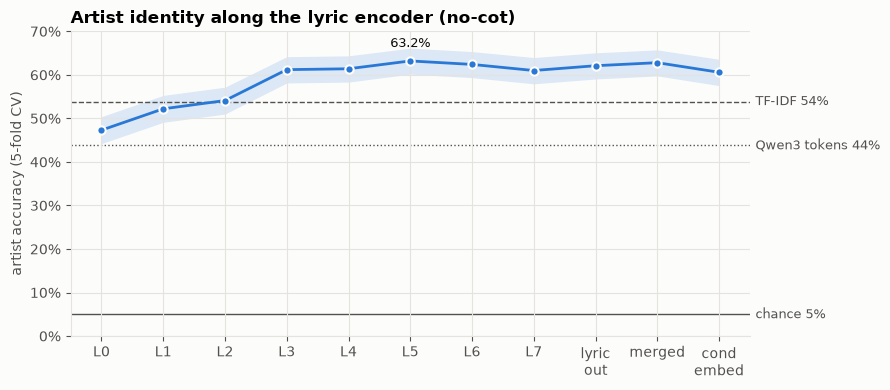

In [3]:
path = [*[f"lyric_L{i}" for i in range(8)], "lyric_out", "merged_out", "cond_embed_out"]
labels = [*[f"L{i}" for i in range(8)], "lyric\nout", "merged", "cond\nembed"]
x = range(len(path))

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(x, results.loc[path, "ci_low"], results.loc[path, "ci_high"], color=SERIES[0], alpha=0.15, linewidth=0)
ax.plot(x, acc[path], color=SERIES[0], marker="o", markersize=6, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
best = acc[path].idxmax()
ax.annotate(
    f"{acc[best]:.1%}",
    (path.index(best), acc[best]),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center",
    fontsize=9,
    color=INK,
)
reference_line(ax, acc["tfidf"], "TF-IDF")
reference_line(ax, acc["qwen3_tokens"], "Qwen3 tokens", style=":")
reference_line(ax, CHANCE, "chance", style="-")
ax.set_xticks(list(x), labels)
ax.set_ylim(0, 0.7)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("artist accuracy (5-fold CV)")
ax.set_title(f"Artist identity along the lyric encoder ({CONFIG})")
fig.tight_layout()

## DiT layers

The ten hooked DiT layers (five sliding/full pairs). `K` and `V` are the cross-attention projections of the
conditioning sequence; the three audio-latent states are averaged over the 8 denoising steps.

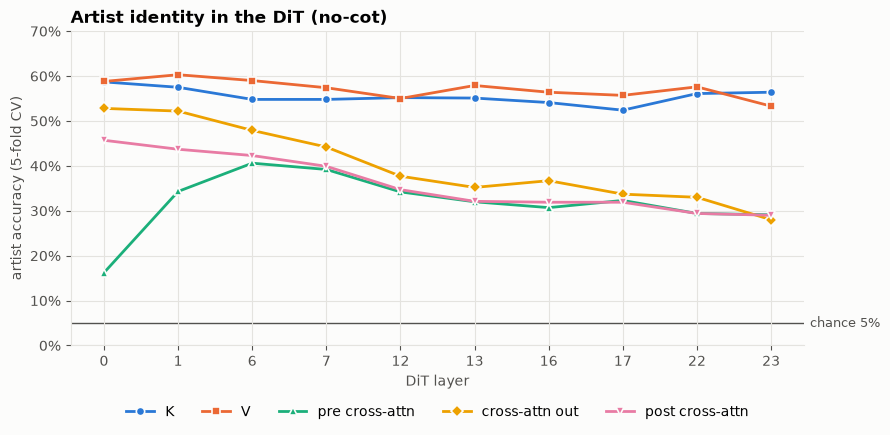

,K,V,pre cross-attn,cross-attn out,post cross-attn
DiT layer,,,,,
0,58.7%,58.8%,16.2%,52.8%,45.7%
1,57.5%,60.3%,34.3%,52.2%,43.7%
6,54.8%,59.0%,40.6%,47.9%,42.3%
7,54.8%,57.4%,39.2%,44.2%,39.9%
12,55.2%,55.0%,34.2%,37.7%,34.7%
13,55.1%,57.9%,32.0%,35.2%,32.1%
16,54.1%,56.4%,30.7%,36.7%,31.9%
17,52.4%,55.7%,32.3%,33.7%,31.9%
22,56.1%,57.6%,29.4%,33.0%,29.4%


In [4]:
series = {
    "K": [f"k_{l}" for l in DIT_LAYERS],
    "V": [f"v_{l}" for l in DIT_LAYERS],
    "pre cross-attn": [f"dit_{l}_pre_xattn_mean" for l in DIT_LAYERS],
    "cross-attn out": [f"dit_{l}_xattn_out_mean" for l in DIT_LAYERS],
    "post cross-attn": [f"dit_{l}_post_xattn_mean" for l in DIT_LAYERS],
}
markers = ["o", "s", "^", "D", "v"]
x = range(len(DIT_LAYERS))

fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, points), color, marker in zip(series.items(), SERIES, markers):
    ax.plot(
        x,
        acc[points],
        color=color,
        marker=marker,
        markersize=6,
        label=name,
        markeredgecolor="#fcfcfb",
        markeredgewidth=1.2,
    )
reference_line(ax, CHANCE, "chance", style="-")
ax.set_xticks(list(x), [str(l) for l in DIT_LAYERS])
ax.set_xlabel("DiT layer")
ax.set_ylim(0, 0.7)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("artist accuracy (5-fold CV)")
ax.set_title(f"Artist identity in the DiT ({CONFIG})")
ax.legend(loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()
plt.show()

# The same numbers as a table (accuracy per DiT layer).
pd.DataFrame(
    {name: acc[points].to_numpy() for name, points in series.items()}, index=pd.Index(DIT_LAYERS, name="DiT layer")
).style.format("{:.1%}")

## Denoising steps

Audio-latent states per denoising step, averaged over the ten DiT layers (step 0 is the first, noisiest step).

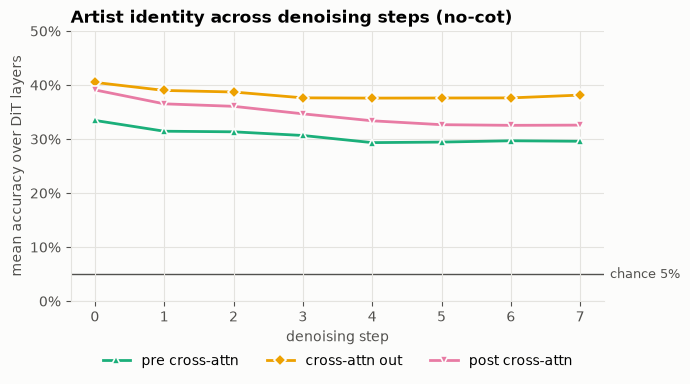

In [5]:
steps = range(8)
fig, ax = plt.subplots(figsize=(7, 4))
for (name, point), color, marker in zip(
    {"pre cross-attn": "pre_xattn", "cross-attn out": "xattn_out", "post cross-attn": "post_xattn"}.items(),
    SERIES[2:5],
    markers[2:5],
):
    curve = [acc[[f"dit_{l}_{point}_t{t}" for l in DIT_LAYERS]].mean() for t in steps]
    ax.plot(
        steps,
        curve,
        color=color,
        marker=marker,
        markersize=6,
        label=name,
        markeredgecolor="#fcfcfb",
        markeredgewidth=1.2,
    )
reference_line(ax, CHANCE, "chance", style="-")
ax.set_xticks(list(steps))
ax.set_xlabel("denoising step")
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("mean accuracy over DiT layers")
ax.set_title(f"Artist identity across denoising steps ({CONFIG})")
ax.legend(loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()

## Per artist

Accuracy per artist at the best point. This is the probe-side number for the RQ1 correlation (probe accuracy vs.
similarity to the reference set). Each artist has 50 songs, so one song is 2 percentage points.

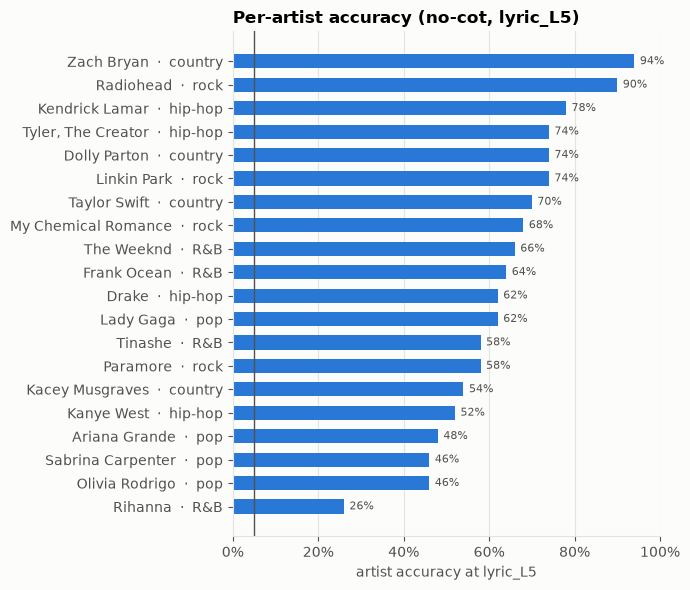

In [6]:
POINT = acc[[f"lyric_L{i}" for i in range(8)] + ["lyric_out"]].idxmax()
genre = {}
for path in sorted(LYRICS_DIR.glob("lyrics_*.csv")):
    genre.update({r["artist"]: r["genre"] for r in load_records(path)})

rows = per_artist[per_artist["point"] == POINT].sort_values("accuracy")
fig, ax = plt.subplots(figsize=(7, 6))
y = range(len(rows))
ax.barh(y, rows["accuracy"], height=0.6, color=SERIES[0])
for i, value in zip(y, rows["accuracy"]):
    ax.annotate(
        f"{value:.0%}", (value, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK_2
    )
ax.set_yticks(list(y), [f"{a}  ·  {genre.get(a, '?')}" for a in rows["artist"]])
ax.axvline(CHANCE, color=INK_2, linewidth=1)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.set_xlabel(f"artist accuracy at {POINT}")
ax.set_title(f"Per-artist accuracy ({CONFIG}, {POINT})")
fig.tight_layout()

## Observations (no-cot, 20 artists, 1000 songs, 2026-11-07)

- The artist is decodable from the lyrics alone: 62-63% from lyric encoder layer L5 to the conditioning sequence
  (`merged_out`) vs. 5% chance, p = 0.001 (the smallest possible with 1000 permutations).
- The lyric encoder adds information over the words themselves: from L3 on it beats TF-IDF (54%) and the mean Qwen3
  token embedding (44%, the encoder's own input). Accuracy rises over the first layers and plateaus from L3.
- The cross-attention K/V projections keep 52-60%, since they are computed directly from the conditioning sequence.
  In the audio-latent states the signal is weaker (16-53% averaged over steps), strongest right after
  cross-attention in the first layers, and fades with depth and over the first denoising steps.
- Controls behave: `text_out` and `timbre_out` are exactly at chance (p = 1).
- Per artist the spread is wide (26% Rihanna to 94% Zach Bryan), which is what RQ1 needs to correlate with copying.
- The first run (400 songs, 20 per artist, Johnny Cash instead of Zach Bryan) gave the same picture with about
  7 points lower accuracy everywhere: 55.5% at `lyric_out`, TF-IDF 42%.
